In [4]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:

os.chdir(r"C:\LABS\week5\lab-eda-univariate")

In [6]:
csv = "amz_uk_price_prediction_dataset.csv" 
df = pd.read_csv("amz_uk_price_prediction_dataset.csv", usecols=["category"])
df = df.dropna(subset=['category'])
df['category'] = df['category'].astype('string').str.strip()

freq = (df['category']
        .value_counts()              
        .rename_axis('category')
        .reset_index(name='count'))
freq

freq.head(5)

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


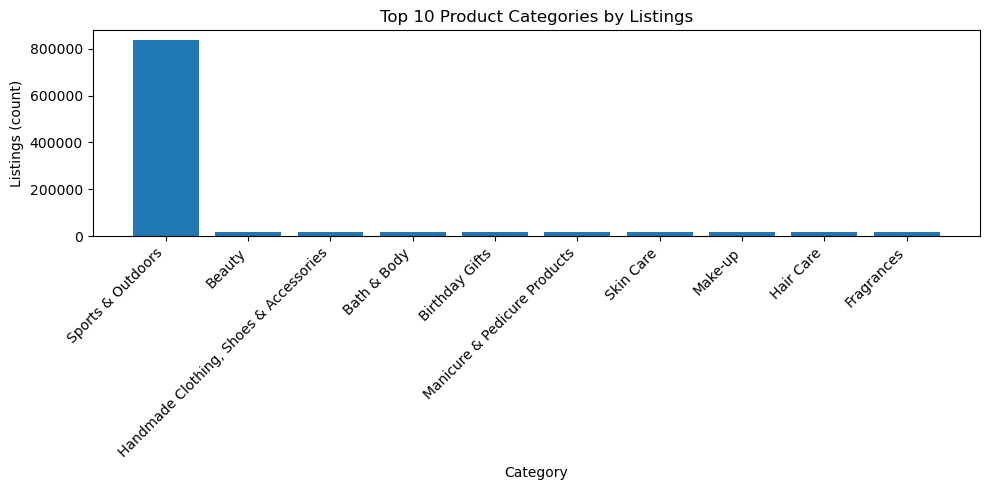

In [7]:
topN = 10
plt.figure(figsize=(10,5))
plt.bar(freq['category'].head(topN), freq['count'].head(topN))
plt.xticks(rotation=45, ha='right')
plt.xlabel('Category'); plt.ylabel('Listings (count)')
plt.title(f'Top {topN} Product Categories by Listings')
plt.tight_layout()

([<matplotlib.patches.Wedge at 0x1a646549550>,
 [Text(-1.061989487463534, 0.2866676272566199, 'Sports & Outdoors'),
  Text(0.9852467003838558, -0.48917168702074837, 'Beauty'),
  Text(1.0412847474771803, -0.3545787284530543, 'Handmade Clothing, Shoes & Accessories'),
  Text(1.0788688426253243, -0.21457404412531686, 'Bath & Body'),
  Text(1.0976548098889691, -0.07179079556329825, 'Birthday Gifts')],
 [Text(-0.5792669931619276, 0.15636416032179262, '91.6%'),
  Text(0.5374072911184667, -0.2668209201931354, '2.1%'),
  Text(0.5679734986239164, -0.19340657915621143, '2.1%'),
  Text(0.5884739141592678, -0.11704038770471828, '2.1%'),
  Text(0.5987208053939831, -0.039158615761799034, '2.1%')])

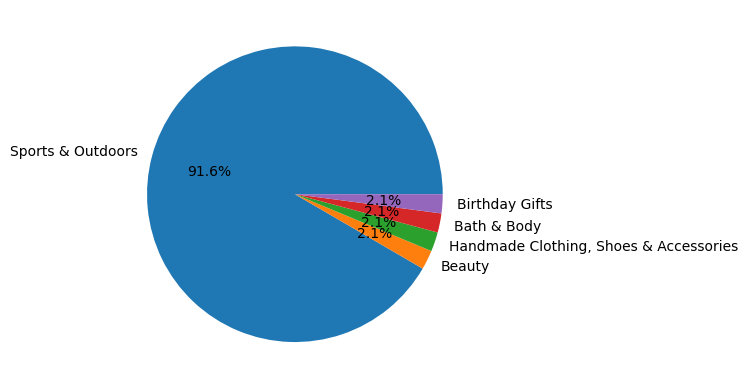

In [8]:
top = freq.head(5)
plt.pie(top['count'], labels=top['category'], autopct='%1.1f%%')

Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [9]:
prices = pd.read_csv("amz_uk_price_prediction_dataset.csv", usecols=["price"])
prices['price'] = pd.to_numeric(prices['price'], errors='coerce')
prices = prices.dropna(subset=['price'])

mean_price   = round(prices['price'].mean(), 2)
median_price = round(prices['price'].median(), 2)
mode_price   = round(prices['price'].mode().iloc[0], 2)

#Results
print("Average price point (mean): GBP", mean_price)
print("Median price:", "GBP", median_price)
print("Most common price point (mode): GBP", mode_price)

#Compare with mode 
if mean_price > mode_price:
    comp = "Mean > mode → right-skewed: a few high-priced items pull the average up."
elif mean_price < mode_price:
    comp = "Mean < mode → left-skewed: some very low prices pull the average down."
else:
    comp = "Mean ≈ mode → roughly symmetric price distribution."
print("Comparison:", comp)

Average price point (mean): GBP 89.24
Median price: GBP 19.09
Most common price point (mode): GBP 9.99
Comparison: Mean > mode → right-skewed: a few high-priced items pull the average up.


In [10]:
round(prices['price'].mean(), 2), round(prices['price'].mode().iloc[0], 2)

(np.float64(89.24), np.float64(9.99))

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [11]:
ratings = pd.read_csv("amz_uk_price_prediction_dataset.csv", usecols=["stars"])
ratings["stars"] = pd.to_numeric(ratings["stars"], errors="coerce")
ratings = ratings.dropna(subset=["stars"])

In [12]:
ratings["stars"].value_counts().sort_index()

stars
0.0    1225641
1.0       8484
1.1          3
1.2         23
1.3         78
1.4        149
1.5        404
1.6        147
1.7        177
1.8        249
1.9        300
2.0       3901
2.1        540
2.2        602
2.3        734
2.4       1060
2.5       2103
2.6       1579
2.7       2104
2.8       2306
2.9       3341
3.0      12819
3.1       4679
3.2       5771
3.3       8269
3.4      10355
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.0      66089
4.1      65115
4.2      86871
4.3     112564
4.4     136165
4.5     151577
4.6     136995
4.7      94566
4.8      41858
4.9      11081
5.0     128492
Name: count, dtype: int64

C:\Users\Lalo\AppData\Local\Temp\ipykernel_13224\780392850.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="stars", data=ratings, palette="Blues")


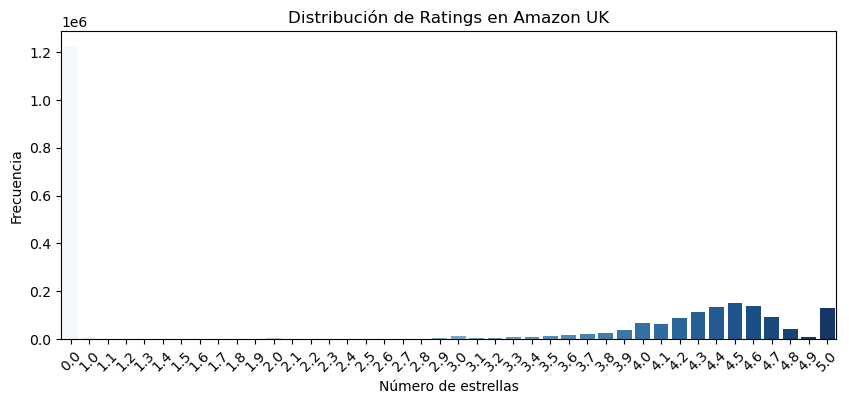

In [13]:
plt.figure(figsize=(10,4))
sns.countplot(x="stars", data=ratings, palette="Blues")

plt.title("Distribución de Ratings en Amazon UK")
plt.xlabel("Número de estrellas")
plt.ylabel("Frecuencia")
plt.xticks(rotation=45)
plt.show()

In [14]:
ratings["stars"].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

The distribution of ratings in Amazon UK shows a clear concentration in higher values (especially between 4 and 5 stars). This suggests a positive trend in product evaluations, with relatively few low ratings.